# Tabular — Deep Learning (Klasifikasi, MLP PyTorch)
**Kapan dipakai:** ingin mencoba neural network di data tabel. Biasanya LightGBM/CatBoost
lebih kuat di tabel, tapi MLP berguna untuk ensembling atau kalau juri meminta deep learning.

**Langkah:**
1. Kolom disiapkan dengan sklearn (isi yang kosong, samakan skala, one-hot).
2. MLP (beberapa lapisan Linear + ReLU) dilatih dengan PyTorch, per batch.
3. Kelas tebakan = output dengan nilai terbesar.

**Data demo:** Titanic (target `survived`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch import nn

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/titanic_train.csv"
TEST_CSV = f"{DATA_FOLDER}/titanic_test.csv"

TARGET = "survived"
NUM_COLS = ["pclass", "age", "sibsp", "parch", "fare"]
CAT_COLS = ["sex", "embarked", "who", "deck"]
EPOCHS = 100             # berapa kali seluruh data train dilihat model
BATCH_SIZE = 64          # jumlah baris per langkah belajar
LEARNING_RATE = 1e-3
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (712, 16) | test: (179, 15)


,id,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,693,1,3,male,NaN,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True
1,482,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True
2,528,0,1,male,NaN,0,0,221.7792,S,First,man,True,C,Southampton,no,True
3,856,1,3,female,18.0,0,1,9.3500,S,Third,woman,False,NaN,Southampton,yes,False
4,802,1,2,female,31.0,1,1,26.2500,S,Second,woman,False,NaN,Southampton,yes,False


## Split + siapkan kolom
PyTorch butuh angka float32, jadi hasil `preprocess` diubah dengan `.astype(np.float32)`.

In [4]:
X = train[NUM_COLS + CAT_COLS]
y = train[TARGET].values
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

num_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])
X_train_ready = preprocess.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocess.transform(X_val).astype(np.float32)

N_FEATURES = X_train_ready.shape[1]
N_CLASSES = len(np.unique(y))
print(N_FEATURES, "feature,", N_CLASSES, "kelas")

20 feature, 2 kelas


## Model
`make_model()` membuat MLP baru (bobot acak). Dipanggil lagi saat latih ulang.
Pilih SATU `return`: hapus `#` di blok yang ingin dipakai, beri `#` pada blok lain.
Dropout = mematikan sebagian neuron secara acak saat latih, supaya tidak menghafal.

In [5]:
def make_model():
    return nn.Sequential(
        nn.Linear(N_FEATURES, 128), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, N_CLASSES),
    )
    # return nn.Sequential(nn.Linear(N_FEATURES, 32), nn.ReLU(), nn.Linear(32, N_CLASSES))
    # return nn.Sequential(
    #     nn.Linear(N_FEATURES, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
    #     nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
    #     nn.Linear(128, N_CLASSES),
    # )


# coba: tampilkan susunan lapisan
print(make_model())

Sequential(
  (0): Linear(in_features=20, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=64, out_features=2, bias=True)
)


## Latih
Tiap epoch: acak urutan baris, potong per batch, hitung loss, perbaiki bobot.
Grafik: loss batch terakhir tiap epoch, seharusnya turun.

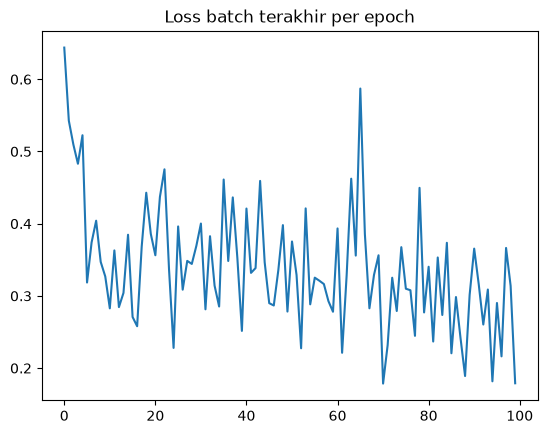

In [6]:
def train_model(X_ready, y_values):
    model = make_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    X_tensor = torch.tensor(X_ready, device=DEVICE)
    y_tensor = torch.tensor(y_values, dtype=torch.long, device=DEVICE)
    loss_history = []
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(len(X_tensor), device=DEVICE)
        for i in range(0, len(X_tensor), BATCH_SIZE):
            batch = order[i:i + BATCH_SIZE]
            loss = nn.functional.cross_entropy(model(X_tensor[batch]), y_tensor[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        loss_history.append(loss.item())
    return model, loss_history


model, loss_history = train_model(X_train_ready, y_train)
plt.plot(loss_history)
plt.title("Loss batch terakhir per epoch")
plt.show()

## Evaluasi di validasi

In [7]:
def predict_classes(model, X_ready):
    model.eval()
    with torch.no_grad():
        outputs = model(torch.tensor(X_ready, device=DEVICE))
    classes = outputs.argmax(1)
    return classes.cpu().numpy()


val_predictions = predict_classes(model, X_val_ready)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))

F1 macro: 0.8187
              precision    recall  f1-score   support

           0       0.84      0.90      0.87        88
           1       0.82      0.73      0.77        55

    accuracy                           0.83       143
   macro avg       0.83      0.81      0.82       143
weighted avg       0.83      0.83      0.83       143



## Latih ulang di semua data + submission

In [8]:
X_all_ready = preprocess.fit_transform(X).astype(np.float32)
X_test_ready = preprocess.transform(test[NUM_COLS + CAT_COLS]).astype(np.float32)
model, loss_history = train_model(X_all_ready, y)
predictions = predict_classes(model, X_test_ready)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["survived"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,survived
0,566,0
1,161,0
2,554,0
3,861,0
4,242,1
